# Mortgage default exploratory analysis

This notebook loads the raw PostgreSQL table, separates records by target availability, and summarizes outcomes by observation year. It does not modify the database or choose a train/validation/test split.

In [1]:
import os
from pathlib import Path

import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import URL, create_engine

pd.set_option("display.max_columns", None)

## 1. Load the PostgreSQL table

Credentials are read from the Git-ignored `.env` file. The query is read-only, and the password is never displayed.

In [2]:
repo_root = Path.cwd()
if not (repo_root / ".env").exists():
    repo_root = repo_root.parent

env_path = repo_root / ".env"
if not env_path.exists():
    raise FileNotFoundError("Could not find the repository .env file.")

load_dotenv(env_path)
required_settings = ["PGHOST", "PGPORT", "PGDATABASE", "PGUSER", "PGPASSWORD"]
missing_settings = [name for name in required_settings if not os.getenv(name)]
if missing_settings:
    raise ValueError(f"Missing database settings in .env: {', '.join(missing_settings)}")

database_url = URL.create(
    drivername="postgresql+psycopg",
    username=os.environ["PGUSER"],
    password=os.environ["PGPASSWORD"],
    host=os.environ["PGHOST"],
    port=int(os.environ["PGPORT"]),
    database=os.environ["PGDATABASE"],
)

engine = create_engine(database_url)
query = """
SELECT
    source_row_id, income, loan_amount, term_length, install_to_inc,
    occup, marital, schufa, num_applic, obs_date, target_var
FROM public.mortgage_default
ORDER BY source_row_id
"""

try:
    mortgage_data = pd.read_sql_query(query, engine)
finally:
    engine.dispose()

mortgage_data["obs_date"] = pd.to_datetime(mortgage_data["obs_date"], errors="raise")
mortgage_data["target_var"] = mortgage_data["target_var"].astype("Int64")

expected_columns = {
    "source_row_id", "income", "loan_amount", "term_length",
    "install_to_inc", "occup", "marital", "schufa",
    "num_applic", "obs_date", "target_var"
}
assert set(mortgage_data.columns) == expected_columns
assert mortgage_data["source_row_id"].is_unique

print(f"Loaded {len(mortgage_data):,} rows and {mortgage_data.shape[1]} columns.")
mortgage_data.head()

Loaded 10,000 rows and 11 columns.


,source_row_id,income,loan_amount,term_length,install_to_inc,occup,marital,schufa,num_applic,obs_date,target_var
0,0,18785.517944,12300.0,67.0,0.009773,None,Single,7106.014471,1.0,2018-07-18,<NA>
1,1,12861.495160,NaN,113.0,0.003509,Employee,Divorced,7694.806894,1.0,2018-07-16,0
2,2,14886.776342,10700.0,NaN,0.013310,Worker,Single,7142.496338,1.0,2010-12-21,1
3,3,NaN,33000.0,112.0,0.004761,Employee,Single,7446.170612,1.0,2015-11-05,0
4,4,15897.753807,19900.0,59.0,0.021216,Worker,Separated,7241.656646,1.0,2015-07-13,1


## 2. Separate labelled and unlabelled records

Only records with a known `target_var` can be used for supervised model development. Unlabelled records are retained separately for possible future scoring.

In [3]:
labelled_data = mortgage_data.loc[mortgage_data["target_var"].notna()].copy()
unlabelled_data = mortgage_data.loc[mortgage_data["target_var"].isna()].copy()

assert len(labelled_data) + len(unlabelled_data) == len(mortgage_data)
assert labelled_data["target_var"].notna().all()
assert unlabelled_data["target_var"].isna().all()
assert labelled_data["source_row_id"].is_unique
assert unlabelled_data["source_row_id"].is_unique

partition_summary = pd.DataFrame(
    {
        "partition": ["Labelled (model development)", "Unlabelled (future scoring)"],
        "records": [len(labelled_data), len(unlabelled_data)],
    }
)
partition_summary["pct_of_all_records"] = (
    100 * partition_summary["records"] / len(mortgage_data)
).round(2)
partition_summary

,partition,records,pct_of_all_records
0,Labelled (model development),9436,94.36
1,Unlabelled (future scoring),564,5.64


## 3. Examine observations and outcomes by year

This table supports a later chronological split decision. `default_rate_pct` uses known outcomes only. The `Missing date` row is kept separate because those records cannot be assigned to a chronological period.

In [4]:
yearly_data = mortgage_data.assign(
    observation_year=mortgage_data["obs_date"].dt.year.astype("Int64")
)

yearly_summary = (
    yearly_data.groupby("observation_year", dropna=False)
    .agg(
        records=("source_row_id", "size"),
        known_outcomes=("target_var", "count"),
        defaults=("target_var", lambda values: values.eq(1).sum()),
    )
    .reset_index()
)
yearly_summary["non_defaults"] = (
    yearly_summary["known_outcomes"] - yearly_summary["defaults"]
)
yearly_summary["missing_outcomes"] = (
    yearly_summary["records"] - yearly_summary["known_outcomes"]
)
yearly_summary["default_rate_pct"] = (
    100 * yearly_summary["defaults"] / yearly_summary["known_outcomes"]
).round(2)
yearly_summary["observation_period"] = (
    yearly_summary["observation_year"].astype("string").fillna("Missing date")
)
yearly_summary = yearly_summary[
    ["observation_period", "records", "known_outcomes", "defaults",
     "non_defaults", "missing_outcomes", "default_rate_pct"]
]

assert yearly_summary["records"].sum() == len(mortgage_data)
assert yearly_summary["known_outcomes"].sum() == len(labelled_data)
assert yearly_summary["defaults"].sum() == labelled_data["target_var"].eq(1).sum()
yearly_summary

,observation_period,records,known_outcomes,defaults,non_defaults,missing_outcomes,default_rate_pct
0,2008,793,753,96,657,40,12.75
1,2009,828,780,108,672,48,13.85
2,2010,892,842,152,690,50,18.05
3,2011,855,800,128,672,55,16.0
4,2012,842,795,113,682,47,14.21
5,2013,889,843,132,711,46,15.66
6,2014,882,841,119,722,41,14.15
7,2015,822,768,125,643,54,16.28
8,2016,885,838,146,692,47,17.42
9,2017,913,863,137,726,50,15.87


## 4. Freeze the chronological split

The split is fixed before further exploration:

- **Training:** 2008–2015
- **Validation:** 2016
- **Test:** 2017–2018
- **Set aside:** labelled records with missing observation dates
- **Unlabelled:** retained separately for possible future scoring

The test set must remain untouched during exploration, feature selection, preprocessing decisions, and model tuning. Subsequent exploratory cells should use `development_data`, which contains only training and validation records.

In [5]:
TRAIN_END_YEAR = 2015
VALIDATION_YEAR = 2016
TEST_YEARS = (2017, 2018)

labelled_years = labelled_data["obs_date"].dt.year
training_data = labelled_data.loc[labelled_years.le(TRAIN_END_YEAR)].copy()
validation_data = labelled_data.loc[labelled_years.eq(VALIDATION_YEAR)].copy()
test_data = labelled_data.loc[labelled_years.isin(TEST_YEARS)].copy()
missing_date_data = labelled_data.loc[labelled_data["obs_date"].isna()].copy()

# Use this dataset for subsequent EDA. Do not use test_data for exploration.
development_data = (
    pd.concat([training_data, validation_data], ignore_index=True)
    .sort_values(["obs_date", "source_row_id"])
    .reset_index(drop=True)
)

split_frames = {
    "Training (2008–2015)": training_data,
    "Validation (2016)": validation_data,
    "Test (2017–2018)": test_data,
    "Set aside (missing date)": missing_date_data,
}
split_id_sets = {
    name: set(frame["source_row_id"]) for name, frame in split_frames.items()
}
for name, ids in split_id_sets.items():
    other_ids = set().union(*(value for key, value in split_id_sets.items() if key != name))
    assert ids.isdisjoint(other_ids), f"{name} overlaps another split"

assert set().union(*split_id_sets.values()) == set(labelled_data["source_row_id"])
assert set(development_data["source_row_id"]) == (
    split_id_sets["Training (2008–2015)"]
    | split_id_sets["Validation (2016)"]
)
assert set(development_data["source_row_id"]).isdisjoint(
    split_id_sets["Test (2017–2018)"]
)

split_summary = pd.DataFrame(
    [
        {
            "split": name,
            "records": len(frame),
            "defaults": int(frame["target_var"].eq(1).sum()),
            "default_rate_pct": round(100 * frame["target_var"].mean(), 2),
            "earliest_date": frame["obs_date"].min(),
            "latest_date": frame["obs_date"].max(),
        }
        for name, frame in split_frames.items()
    ]
)
split_summary

,split,records,defaults,default_rate_pct,earliest_date,latest_date
0,Training (2008–2015),6422,973,15.15,2008-01-02,2015-12-31
1,Validation (2016),838,146,17.42,2016-01-02,2016-12-30
2,Test (2017–2018),1641,249,15.17,2017-01-01,2018-12-31
3,Set aside (missing date),535,86,16.07,NaT,NaT


### Development-only exploration rule

From this point onward, exploratory plots and feature investigations must read from `development_data`. Use `training_data` to fit preprocessing and models, `validation_data` to compare modelling choices and thresholds, and `test_data` only once for final evaluation after all choices are fixed.

## 5. Numeric feature distributions on development data

For each continuous numeric feature, the three panels show its overall distribution, its distribution by observed outcome, and default rates across five approximately equal-sized quantile groups. The default-rate panel includes 95% Wilson confidence intervals and a separate missing-value group. Wider intervals indicate greater uncertainty.

These charts are descriptive. They can reveal skew, outliers, nonlinear patterns, and candidate predictors, but they do not establish causation or out-of-sample predictive value.

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

NUMERIC_FEATURES = {
    "income": "Income",
    "loan_amount": "Loan amount",
    "term_length": "Term length",
    "install_to_inc": "Instalment / income",
    "schufa": "SCHUFA score",
}

# Leakage guard: every chart below receives development_data only.
assert set(development_data["source_row_id"]).isdisjoint(
    set(test_data["source_row_id"])
)

In [7]:
def wilson_interval(defaults, records, z=1.96):
    """Return a Wilson confidence interval for a binomial proportion."""
    proportion = defaults / records
    denominator = 1 + z**2 / records
    centre = (proportion + z**2 / (2 * records)) / denominator
    margin = (
        z
        * np.sqrt(proportion * (1 - proportion) / records + z**2 / (4 * records**2))
        / denominator
    )
    return centre - margin, centre + margin


def quantile_default_summary(data, feature, quantiles=5):
    """Summarize default rates by quantile, with missing values separate."""
    available = data.loc[data[feature].notna(), [feature, "target_var"]].copy()
    available["quantile_number"] = (
        pd.qcut(available[feature], q=quantiles, labels=False, duplicates="drop") + 1
    )
    summary = (
        available.groupby("quantile_number", observed=True)
        .agg(
            range_min=(feature, "min"),
            range_max=(feature, "max"),
            records=("target_var", "size"),
            defaults=("target_var", "sum"),
        )
        .reset_index()
    )
    summary["group"] = summary["quantile_number"].map(
        lambda value: f"Q{int(value)}"
    )

    missing = data.loc[data[feature].isna(), "target_var"]
    if not missing.empty:
        summary = pd.concat(
            [
                summary,
                pd.DataFrame(
                    {
                        "quantile_number": [np.nan],
                        "range_min": [np.nan],
                        "range_max": [np.nan],
                        "records": [len(missing)],
                        "defaults": [int(missing.eq(1).sum())],
                        "group": ["Missing"],
                    }
                ),
            ],
            ignore_index=True,
        )

    intervals = [
        wilson_interval(defaults, records)
        for defaults, records in zip(summary["defaults"], summary["records"])
    ]
    summary["default_rate_pct"] = 100 * summary["defaults"] / summary["records"]
    summary["ci_lower_pct"] = [100 * interval[0] for interval in intervals]
    summary["ci_upper_pct"] = [100 * interval[1] for interval in intervals]
    return summary


def plot_numeric_feature(data, feature, label):
    """Plot distribution, outcome box plot, and quantile default rates."""
    assert set(data["source_row_id"]).isdisjoint(set(test_data["source_row_id"]))
    plot_data = data.loc[:, [feature, "target_var"]].copy()
    plot_data["outcome"] = plot_data["target_var"].map(
        {0: "No default", 1: "Default"}
    )
    rate_summary = quantile_default_summary(data, feature)

    figure, axes = plt.subplots(1, 3, figsize=(18, 4.8))
    sns.histplot(data=plot_data, x=feature, bins=30, ax=axes[0], color="#3973AC")
    axes[0].set(title=f"{label}: distribution", xlabel=label, ylabel="Records")

    sns.boxplot(
        data=plot_data, x="outcome", y=feature,
        order=["No default", "Default"], ax=axes[1], color="#8AB6D6"
    )
    axes[1].set(title=f"{label} by outcome", xlabel="Observed outcome", ylabel=label)

    positions = np.arange(len(rate_summary))
    rates = rate_summary["default_rate_pct"].to_numpy()
    errors = np.vstack(
        [
            rates - rate_summary["ci_lower_pct"].to_numpy(),
            rate_summary["ci_upper_pct"].to_numpy() - rates,
        ]
    )
    axes[2].bar(positions, rates, color="#D9822B", alpha=0.85)
    axes[2].errorbar(positions, rates, yerr=errors, fmt="none", ecolor="black", capsize=4)
    axes[2].set_xticks(positions, rate_summary["group"])
    axes[2].set(title=f"Default rate by {label.lower()} group", xlabel="Quantile group", ylabel="Default rate (%)")
    for position, rate, records in zip(positions, rates, rate_summary["records"]):
        axes[2].text(position, rate, f"n={records:,}", ha="center", va="bottom", fontsize=8)

    figure.suptitle(f"Development data only — {label}", fontsize=14, fontweight="bold")
    figure.tight_layout()
    plt.show()
    return rate_summary


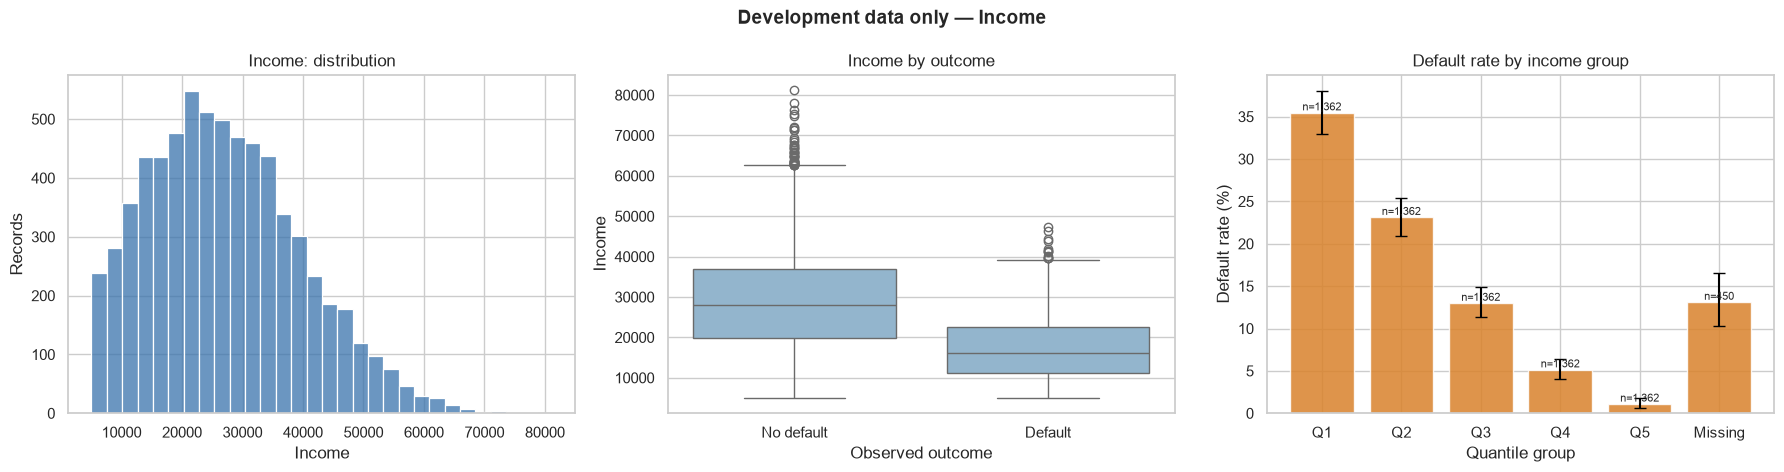

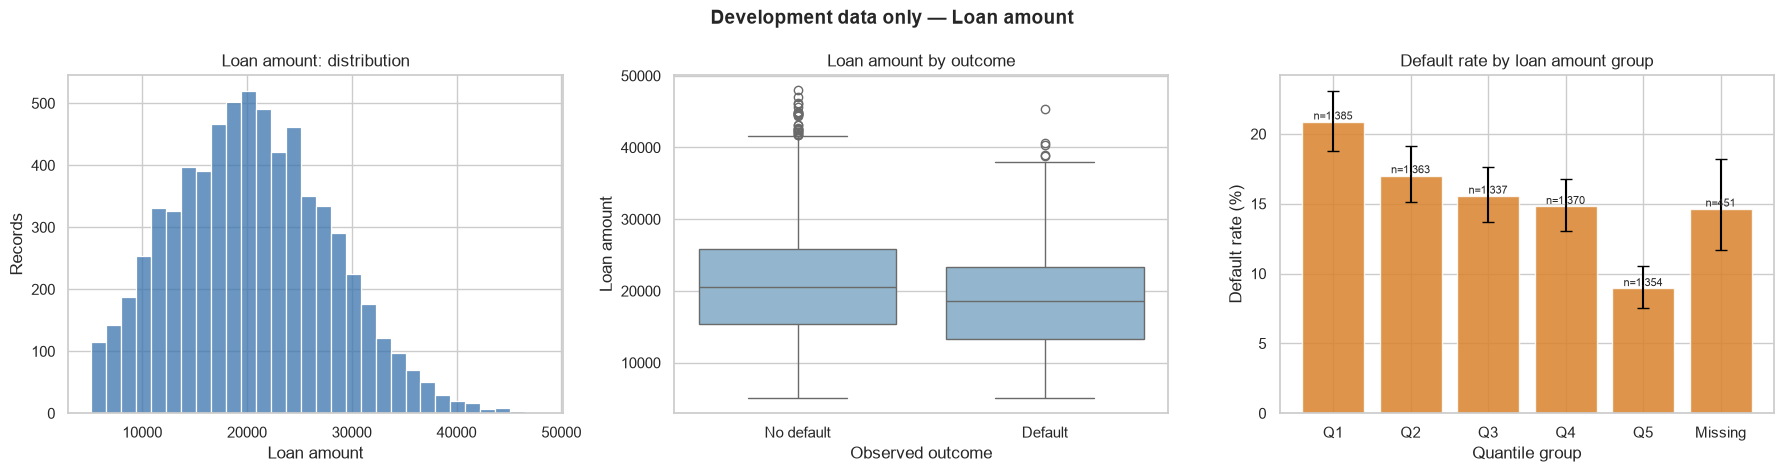

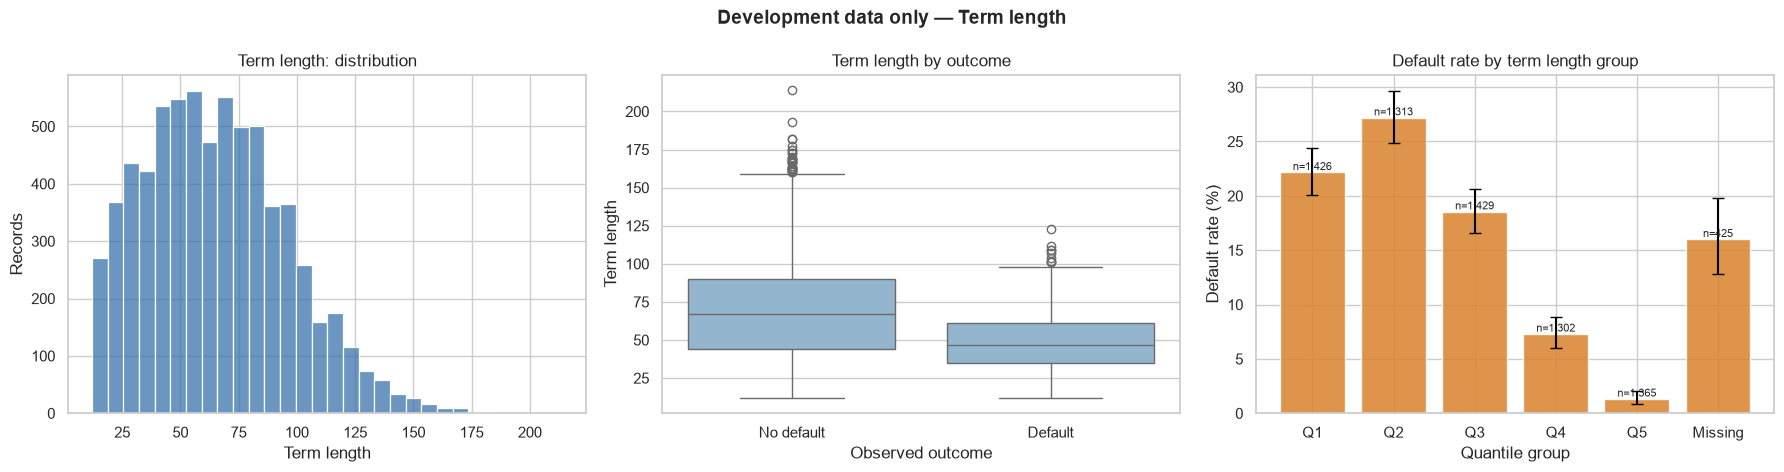

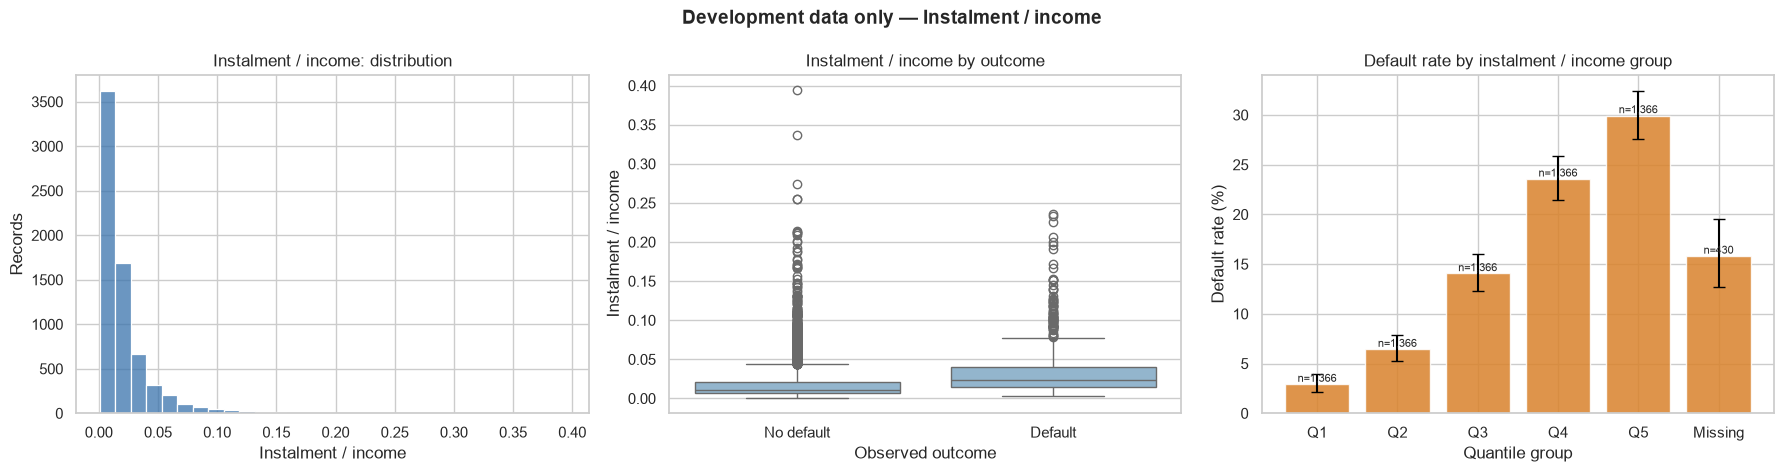

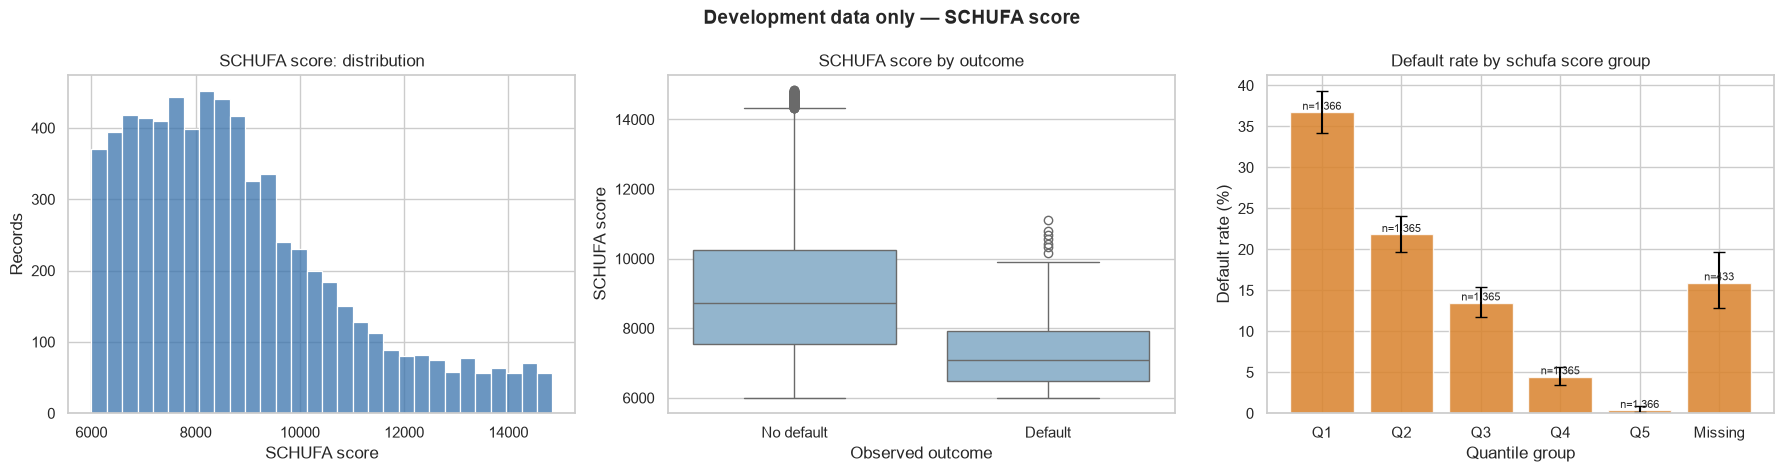

In [8]:
numeric_rate_summaries = {}
for feature, label in NUMERIC_FEATURES.items():
    numeric_rate_summaries[feature] = plot_numeric_feature(
        development_data, feature, label
    )

### Quantile tables

Use the tables below to read exact group ranges, counts, default rates, and uncertainty. Quantile boundaries are learned from development data only. The groups are descriptive and are not yet model features.

In [9]:
numeric_rate_table = pd.concat(
    [summary.assign(feature=feature) for feature, summary in numeric_rate_summaries.items()],
    ignore_index=True,
)
numeric_rate_table = numeric_rate_table[
    ["feature", "group", "range_min", "range_max", "records",
     "defaults", "default_rate_pct", "ci_lower_pct", "ci_upper_pct"]
].round(
    {
        "range_min": 4, "range_max": 4,
        "default_rate_pct": 2, "ci_lower_pct": 2, "ci_upper_pct": 2,
    }
)
numeric_rate_table

,feature,group,range_min,range_max,records,defaults,default_rate_pct,ci_lower_pct,ci_upper_pct
0,income,Q1,5021.6911,15470.8610,1362,483,35.46,32.97,38.04
1,income,Q2,15474.2301,22570.0313,1362,315,23.13,20.97,25.44
2,income,Q3,22577.5304,29468.5564,1362,177,13.0,11.31,14.89
3,income,Q4,29479.4776,37677.1262,1362,70,5.14,4.09,6.44
4,income,Q5,37677.3584,81215.7220,1362,15,1.1,0.67,1.81
5,income,Missing,NaN,NaN,450,59,13.11,10.30,16.54
6,loan_amount,Q1,5100.0000,13700.0000,1385,289,20.87,18.81,23.09
7,loan_amount,Q2,13800.0000,18300.0000,1363,232,17.02,15.12,19.11
8,loan_amount,Q3,18400.0000,22100.0000,1337,208,15.56,13.71,17.60
9,loan_amount,Q4,22200.0000,26900.0000,1370,203,14.82,13.03,16.80


### Numeric-feature conclusions

The development data shows clear, plausible risk ordering for several variables. Default rates fall strongly as **income** and **SCHUFA** increase, while they rise strongly with **instalment-to-income**, making these the clearest candidates for the initial model. **Loan amount** has a weaker decreasing relationship that may overlap with income and affordability. **Term length** is nonlinear: risk peaks in an earlier-middle group and then declines, so a single linear coefficient may not fully represent it.

Missing-value groups generally have default rates near the development average. We will retain the affected records, apply training-set median imputation, and add missing-value indicators so the model can distinguish observed from imputed values. Financial features also contain skew and extremes; these values will be investigated rather than removed automatically. Scaling will support logistic regression, and any log or nonlinear transformations will be compared using validation data.

All five numeric variables remain provisional predictors. Their final value depends on whether they improve validation performance after the other variables are included, because several may contain overlapping information.

## 6. Occupation and applicant-count analysis

The frequency charts show how much development data each category represents. The default-rate charts show historical risk with 95% Wilson confidence intervals and the overall development default rate as a reference. Missing values remain separate. Occupation codes `1`, `2`, and `3` are preserved because their meanings are unknown.

In [10]:
categorical_analysis_data = development_data.copy()
categorical_analysis_data["occupation_group"] = (
    categorical_analysis_data["occup"].astype("string").fillna("Missing")
)
categorical_analysis_data["applicant_group"] = (
    categorical_analysis_data["num_applic"]
    .astype("Int64")
    .astype("string")
    .fillna("Missing")
)

assert set(categorical_analysis_data["source_row_id"]).isdisjoint(
    set(test_data["source_row_id"])
)

occupation_frequency = (
    categorical_analysis_data["occupation_group"]
    .value_counts(dropna=False)
    .rename_axis("occupation")
    .reset_index(name="records")
)
applicant_frequency = (
    categorical_analysis_data["applicant_group"]
    .value_counts(dropna=False)
    .rename_axis("number_of_applicants")
    .reset_index(name="records")
)

### Occupation frequencies

In [11]:
occupation_frequency

,occupation,records
0,Worker,3273
1,Employee,2011
2,Student,1327
3,Missing,440
4,1,78
5,2,70
6,3,61


### Applicant-count frequencies

In [12]:
applicant_frequency

,number_of_applicants,records
0,1,4813
1,2,2025
2,Missing,422


In [13]:
def categorical_default_summary(data, category_column):
    """Return frequency and default-rate statistics for a category."""
    assert set(data["source_row_id"]).isdisjoint(set(test_data["source_row_id"]))
    summary = (
        data.groupby(category_column, dropna=False)
        .agg(
            records=("target_var", "size"),
            defaults=("target_var", "sum"),
        )
        .reset_index()
        .rename(columns={category_column: "category"})
    )
    summary["defaults"] = summary["defaults"].astype(int)
    summary["non_defaults"] = summary["records"] - summary["defaults"]
    summary["dataset_share_pct"] = 100 * summary["records"] / len(data)
    summary["default_rate_pct"] = 100 * summary["defaults"] / summary["records"]
    intervals = [
        wilson_interval(defaults, records)
        for defaults, records in zip(summary["defaults"], summary["records"])
    ]
    summary["ci_lower_pct"] = [100 * interval[0] for interval in intervals]
    summary["ci_upper_pct"] = [100 * interval[1] for interval in intervals]
    return summary.sort_values(["records", "category"], ascending=[False, True]).reset_index(drop=True)


def plot_categorical_feature(summary, label, overall_default_rate):
    """Plot category frequency and default rate side by side."""
    positions = np.arange(len(summary))
    figure, axes = plt.subplots(1, 2, figsize=(15, 5))

    axes[0].bar(positions, summary["records"], color="#3973AC", alpha=0.85)
    axes[0].set_xticks(positions, summary["category"], rotation=30, ha="right")
    axes[0].set(title=f"{label}: frequency", xlabel=label, ylabel="Records")
    for position, records in zip(positions, summary["records"]):
        axes[0].text(position, records, f"{records:,}", ha="center", va="bottom", fontsize=9)

    rates = summary["default_rate_pct"].to_numpy()
    errors = np.vstack(
        [
            rates - summary["ci_lower_pct"].to_numpy(),
            summary["ci_upper_pct"].to_numpy() - rates,
        ]
    )
    axes[1].bar(positions, rates, color="#D9822B", alpha=0.85)
    axes[1].errorbar(positions, rates, yerr=errors, fmt="none", ecolor="black", capsize=4)
    axes[1].axhline(
        overall_default_rate, color="#555555", linestyle="--",
        label=f"Development average: {overall_default_rate:.2f}%"
    )
    axes[1].set_xticks(positions, summary["category"], rotation=30, ha="right")
    axes[1].set(title=f"{label}: default rate", xlabel=label, ylabel="Default rate (%)")
    axes[1].legend()
    for position, rate, records in zip(positions, rates, summary["records"]):
        axes[1].text(position, rate, f"n={records:,}", ha="center", va="bottom", fontsize=8)

    figure.suptitle(f"Development data only — {label}", fontsize=14, fontweight="bold")
    figure.tight_layout()
    plt.show()

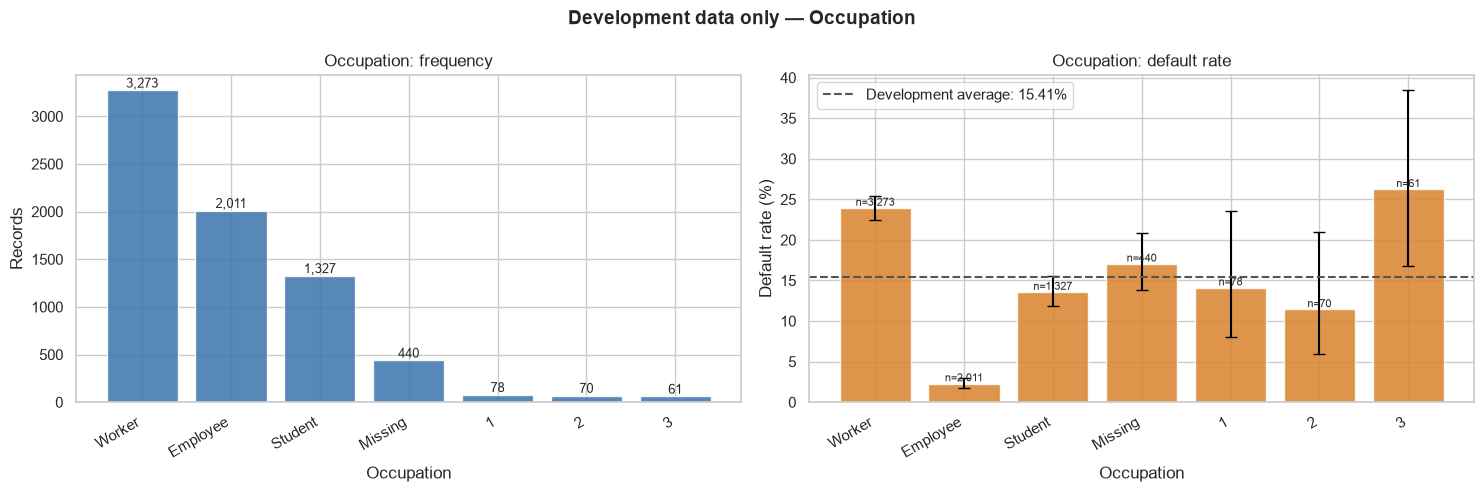

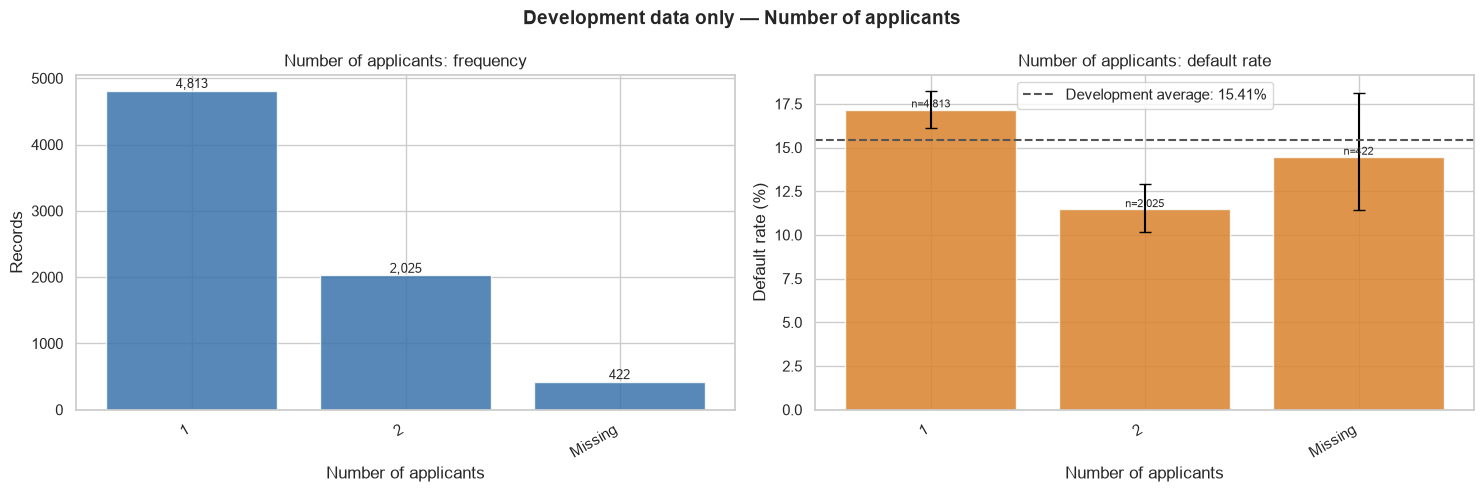

In [14]:
occupation_summary = categorical_default_summary(
    categorical_analysis_data, "occupation_group"
)
applicant_summary = categorical_default_summary(
    categorical_analysis_data, "applicant_group"
)
overall_development_default_rate = 100 * development_data["target_var"].mean()

plot_categorical_feature(
    occupation_summary, "Occupation", overall_development_default_rate
)
plot_categorical_feature(
    applicant_summary, "Number of applicants", overall_development_default_rate
)

### Exact category results

Interpret default rates alongside record counts and confidence intervals. Large differences in small categories are less reliable. These are descriptive associations and do not establish that a category causes default.

In [15]:
category_results = pd.concat(
    [
        occupation_summary.assign(feature="occupation"),
        applicant_summary.assign(feature="number_of_applicants"),
    ],
    ignore_index=True,
)
category_results = category_results[
    ["feature", "category", "records", "dataset_share_pct",
     "defaults", "non_defaults", "default_rate_pct",
     "ci_lower_pct", "ci_upper_pct"]
].round(2)
category_results

,feature,category,records,dataset_share_pct,defaults,non_defaults,default_rate_pct,ci_lower_pct,ci_upper_pct
0,occupation,Worker,3273,45.08,783,2490,23.92,22.49,25.41
1,occupation,Employee,2011,27.7,46,1965,2.29,1.72,3.04
2,occupation,Student,1327,18.28,180,1147,13.56,11.83,15.51
3,occupation,Missing,440,6.06,75,365,17.05,13.82,20.84
4,occupation,1,78,1.07,11,67,14.1,8.06,23.51
5,occupation,2,70,0.96,8,62,11.43,5.91,20.96
6,occupation,3,61,0.84,16,45,26.23,16.84,38.44
7,number_of_applicants,1,4813,66.29,826,3987,17.16,16.12,18.25
8,number_of_applicants,2,2025,27.89,232,1793,11.46,10.14,12.92
9,number_of_applicants,Missing,422,5.81,61,361,14.45,11.42,18.13


### Categorical-feature conclusions

**Occupation** shows substantial differences in default rates, particularly between the large Worker and Employee groups, so it is plausibly useful. The numeric occupation codes `1`, `2`, and `3` have small samples and unknown meanings; they will remain separate and will not be interpreted or merged without documentation. Missing occupation will be retained as an explicit category. Occupation will be one-hot encoded and its contribution and fairness implications will be reviewed during validation.

**Number of applicants** also shows a plausible pattern: joint applications have a lower observed default rate than single applications. Because it has only two observed values and a meaningful missing group, it will be treated as a categorical feature with an explicit missing category rather than mode-imputed.

These are historical associations from development data, not causal findings. Both variables remain provisional until the combined model shows that they improve performance on the 2016 validation period.